# LAB 03 — NHẬN DẠNG TIẾNG NÓI NÂNG CAO VỚI HMM
**CSE457 — Xử lý âm thanh và tiếng nói | Chạy bằng VS Code + Jupyter + Conda**

Notebook bám theo **Lab 3.pdf (11 trang)**: các mục thực hành **A–H**, thí nghiệm **E1–E6**, case study **5 lệnh tiếng Việt**: `mo`, `dong`, `len`, `xuong`, `dung`.

### Kết quả mong đợi
- WAV → silence trimming → pre-emphasis → MFCC 13 + Δ13 + Δ²13 → CMVN → ma trận `T × 39`.
- Huấn luyện **5 Gaussian HMM left-to-right**, Gaussian covariance `diag`, giải mã acoustic likelihood và Viterbi.
- Bảng score, confusion matrix, DTW baseline, 6 thí nghiệm, lexicon parser, unigram/bigram và thử robustness với nhiễu nhẹ.
- Lưu các bảng dưới `results/`, biểu đồ dưới `results/figures/`, mô hình dưới `models/`.

> **Giới hạn dữ liệu:** Tài liệu không cung cấp file WAV, từ điển phone chuẩn hoặc corpus giảng viên. Bạn phải bổ sung WAV thật; lexicon có thể để trống khi chưa có phone inventory; corpus ví dụ được đánh dấu là **DEMO**, phải thay bằng corpus giảng viên để nộp chính thức. Không tự tạo điểm số hay coi dữ liệu demo là kết quả thật.

> **Lưu ý:** Các phần đánh giá chỉ có ý nghĩa khi dữ liệu `test` tách biệt với `train`. Nếu muốn kiểm tra speaker-independent, cần thêm người nói và tách toàn bộ file của một người sang test.

**Bản cập nhật:** tăng cường E3, E6, kiểm tra tất cả Viterbi paths, metadata speaker và reject mặc định tắt; tránh coi corpus/lexicon DEMO là dữ liệu giảng viên.

## 0. Chuẩn bị môi trường trên VS Code
Mở **Anaconda Prompt** hoặc Terminal của VS Code, sử dụng một môi trường Conda riêng (không sửa `base`):

```powershell
conda create -n lab03-hmm python=3.11 -y
conda activate lab03-hmm
python -c "import sys; print(sys.executable)"
python -m pip install numpy scipy matplotlib librosa soundfile scikit-learn hmmlearn pandas ipykernel notebook
python -m ipykernel install --user --name lab03-hmm --display-name "Python (lab03-hmm)"
```

Trong VS Code cài extensions **Python** và **Jupyter**, mở `Lab03.ipynb`, chọn **Select Kernel → Python (lab03-hmm)**. Chạy các ô từ trên xuống. **Chỉ cài thư viện nếu môi trường đang dùng chưa có.**

**Cấu trúc thư mục tối thiểu** đặt cạnh notebook:

```text
Lab03.ipynb

dataset/
  train/
    mo/    mo_01.wav ... mo_06.wav
    dong/  dong_01.wav ... dong_06.wav
    len/   ...
    xuong/ ...
    dung/  ...
  test/
    mo/    mo_07.wav mo_08.wav
    dong/  ...
    len/   ...
    xuong/ ...
    dung/  ...
```

Tài liệu đề xuất **mỗi từ 6 file train + 2 file test/người**, WAV **mono/16 kHz/16-bit PCM**. Tên file có thể khác; chương trình quét `*.wav` theo thư mục.

In [1]:
import sys, importlib.util
print("Python executable:", sys.executable)
print("Python version   :", sys.version.split()[0])
required = ["numpy", "scipy", "matplotlib", "librosa", "soundfile", "sklearn", "hmmlearn", "pandas"]
missing = [m for m in required if importlib.util.find_spec(m) is None]
if missing:
    print("THIẾU THƯ VIỆN:", ", ".join(missing))
    raise ImportError("Hãy chọn kernel Conda phù hợp rồi chạy: python -m pip install " +
                      " ".join("scikit-learn" if m == "sklearn" else m for m in missing))
print("Đủ các thư viện chính. Có thể chạy tiếp.")

Python executable: c:\Users\admin\AppData\Local\Programs\Python\Python310\python.exe
Python version   : 3.10.5
Đủ các thư viện chính. Có thể chạy tiếp.


In [2]:
from pathlib import Path
from collections import Counter
from functools import lru_cache
import hashlib, math, pickle, time, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import soundfile as sf
from hmmlearn.hmm import GaussianHMM
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

SEED = 42
np.random.seed(SEED)
LABELS = ["mo", "dong", "len", "xuong", "dung"]
LABEL_VI = dict(zip(LABELS, ["mở", "đóng", "lên", "xuống", "dừng"]))
SR = 16000
N_MFCC = 13
N_STATES = 5
N_ITER = 80
TOP_DB = 30
DEFAULT_FEATURE = "mfcc39"     # "mfcc13" hoặc "mfcc39"
DATASET_ROOT = Path("dataset")  # có thể đổi thành đường dẫn tuyệt đối: Path(r"D:\Speech\dataset")
TRAIN_DIR = DATASET_ROOT / "train"
TEST_DIR = DATASET_ROOT / "test"
OUT = Path("results")
FIG_DIR = OUT / "figures"
MODEL_DIR = Path("models")
for p in (OUT, FIG_DIR, MODEL_DIR):
    p.mkdir(parents=True, exist_ok=True)

RUN_FULL_COV = False  # Thí nghiệm E3 chỉ bật khi đã bổ sung nhiều dữ liệu
NOISE_SNR_DB = 15.0   # E5: nhiễu Gaussian trắng ở SNR 15 dB
LM_WEIGHTS = [0.0, 0.1, 0.3, 1.0]
# Đổi True nếu muốn mô phỏng quyết định từ chối; chỉ dùng threshold được chỉnh trên validation có OOV.
ENABLE_REJECT_IN_DEMO = False
print("Current working directory:", Path.cwd())
print("Đường dẫn dataset:", DATASET_ROOT.resolve())

Current working directory: c:\xulyamthanh\lab03_2351260688_NguyenNgocTien
Đường dẫn dataset: C:\xulyamthanh\lab03_2351260688_NguyenNgocTien\dataset


## A. Kiểm tra dữ liệu & trích xuất MFCC động
**Nguồn:** mục 2.2, 4.1 và 5.2, trang 2, 6–7.

- Kiểm tra 5 nhãn trong `train`/`test`, số file, WAV mono/16 kHz/16-bit PCM.
- Kiểm tra trùng nội dung train/test bằng SHA-256.
- Trích `MFCC13`, `Δ13`, `Δ²13`; dùng **CMVN cho từng utterance** như code case study.
- Vẽ heatmap của ít nhất hai từ.

Nếu chưa có dữ liệu, cell kiểm tra sẽ dừng và cho biết vị trí cần đặt file; **không tạo audio giả để chấm điểm**.

In [3]:
def wav_paths(split: str, label: str):
    return sorted((DATASET_ROOT / split / label).glob("*.wav"))

rows, hashes = [], {"train": set(), "test": set()}
problems = []
for split in ("train", "test"):
    for label in LABELS:
        paths = wav_paths(split, label)
        min_required = 6 if split == "train" else 2
        if len(paths) < min_required:
            problems.append(f"{split}/{label}: {len(paths)} file (đề xuất >= {min_required})")
        for path in paths:
            try:
                info = sf.info(str(path))
                digest = hashlib.sha256(path.read_bytes()).hexdigest()
                hashes[split].add(digest)
                rows.append({"split": split, "label": label, "file": path.name,
                             "sr": info.samplerate, "channels": info.channels,
                             "subtype": info.subtype, "seconds": round(info.duration, 3)})
            except Exception as exc:
                raise RuntimeError(f"Không đọc được file WAV {path}: {exc}") from exc
inventory = pd.DataFrame(rows)
if inventory.empty:
    raise FileNotFoundError(
        f"Chưa thấy WAV trong {DATASET_ROOT.resolve()}. "
        "Hãy tạo dataset/train/<nhãn>/ và dataset/test/<nhãn>/ theo hướng dẫn ở đầu notebook.")

counts = (inventory.pivot_table(index="label", columns="split", values="file", aggfunc="count")
          .reindex(LABELS).fillna(0).astype(int))
display(counts)
if problems:
    print("LƯU Ý về số lượng:", *problems, sep="\n - ")
if not {"train", "test"}.issubset(set(inventory["split"])) or (counts == 0).any().any():
    raise ValueError("Mỗi lớp bắt buộc có ít nhất 1 file train và 1 file test để chạy đủ Lab.")
if hashes["train"] & hashes["test"]:
    raise ValueError("Phát hiện WAV trùng byte giữa train/test! Cần loại bỏ leakage.")
bad_wav = inventory.loc[(inventory.sr != SR) | (inventory.channels != 1) |
                        (inventory.subtype != "PCM_16")]
if len(bad_wav):
    display(bad_wav)
    raise ValueError("Lab yêu cầu WAV 16kHz, mono, 16-bit PCM. Hãy chuyển định dạng trước khi chạy.")
print(f"Tổng số file: {len(inventory)}. Không thấy trùng byte train/test.")
print("LƯU Ý: kiểm tra người nói riêng; checksum không phát hiện cùng utterance đã đổi định dạng.")
inventory.to_csv(OUT / "data_inventory.csv", index=False, encoding="utf-8-sig")

split,test,train
label,,
mo,2,6
dong,2,6
len,2,6
xuong,2,6
dung,2,6


Tổng số file: 40. Không thấy trùng byte train/test.
LƯU Ý: kiểm tra người nói riêng; checksum không phát hiện cùng utterance đã đổi định dạng.


c:\Users\admin\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


mo_01.wav → shape (39, 39)
dong_01.wav → shape (23, 39)
len_01.wav → shape (42, 39)


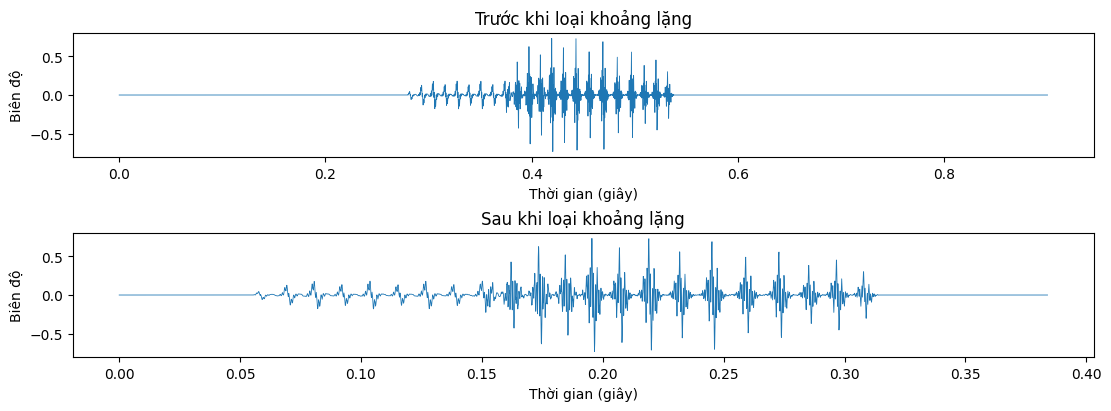

In [4]:
def read_speech(path: str | Path):
    """Đọc âm thanh và cắt khoảng lặng (Lab 3: top_db=30)."""
    y, sr = librosa.load(str(path), sr=SR, mono=True)
    if y.size == 0:
        raise ValueError(f"File âm thanh rỗng: {path}")
    trimmed, idx = librosa.effects.trim(y, top_db=TOP_DB)
    if trimmed.size == 0 or np.max(np.abs(trimmed)) < 1e-9:
        raise ValueError(f"Không đủ tín hiệu tiếng nói trong: {path}")
    return y, trimmed, idx

@lru_cache(maxsize=1200)
def extract_features(path: str, kind="mfcc39", snr_db=None):
    """Trả về (T, 13) hoặc (T, 39); snr_db chỉ dùng trên dữ liệu test ở E5."""
    if kind not in {"mfcc13", "mfcc39"}:
        raise ValueError("kind phải là mfcc13 hoặc mfcc39")
    _, y, _ = read_speech(path)
    if snr_db is not None:
        # Seed phụ thuộc tên file, cho phép chạy lại ra cùng một mức nhiễu.
        seed = int(hashlib.md5(str(path).encode("utf-8")).hexdigest()[:8], 16) + SEED
        rng = np.random.default_rng(seed)
        noise = rng.standard_normal(y.shape)
        rms_sig = np.sqrt(np.mean(y ** 2))
        rms_noise = np.sqrt(np.mean(noise ** 2)) + 1e-12
        noise = noise * rms_sig / (10 ** (float(snr_db) / 20) * rms_noise)
        y = np.clip(y + noise, -1.0, 1.0)
    y = librosa.effects.preemphasis(y, coef=0.97)
    mfcc = librosa.feature.mfcc(
        y=y, sr=SR, n_mfcc=13, n_fft=512, win_length=int(0.025 * SR),
        hop_length=int(0.010 * SR), window="hamming", n_mels=26,
        fmin=20, fmax=SR / 2
    )
    if kind == "mfcc13":
        feat = mfcc.T
    else:
        # Mặc định delta width=9. Với từ quá ngắn, giảm width (số lẻ >=3).
        t = mfcc.shape[1]
        width = min(9, t if t % 2 else t - 1)
        if width < 3:
            raise ValueError(f"Utterance quá ngắn để tính Delta: {path} ({t} frames)")
        d1 = librosa.feature.delta(mfcc, order=1, width=width)
        d2 = librosa.feature.delta(mfcc, order=2, width=width)
        feat = np.vstack([mfcc, d1, d2]).T
    # Utterance-level CMVN: không lấy thống kê của test để chuẩn hóa train.
    feat = np.asarray(feat, dtype=np.float64)
    mu = feat.mean(axis=0, keepdims=True)
    sd = feat.std(axis=0, keepdims=True) + 1e-8
    return (feat - mu) / sd

samples = [str(wav_paths("train", label)[0]) for label in LABELS[:3]]
for p in samples:
    F = extract_features(p)
    print(Path(p).name, "→ shape", F.shape)
    assert F.ndim == 2 and F.shape[1] == 39 and np.isfinite(F).all()

example_path = samples[0]
original, trimmed, trim_idx = read_speech(example_path)
fig, ax = plt.subplots(2, 1, figsize=(11, 4), constrained_layout=True)
ax[0].plot(np.arange(len(original)) / SR, original, linewidth=0.6)
ax[0].set_title("Trước khi loại khoảng lặng")
ax[1].plot(np.arange(len(trimmed)) / SR, trimmed, linewidth=0.6)
ax[1].set_title("Sau khi loại khoảng lặng")
for a in ax:
    a.set_xlabel("Thời gian (giây)")
    a.set_ylabel("Biên độ")
fig.savefig(FIG_DIR / "A_waveform_trim.png", dpi=150)
plt.show()

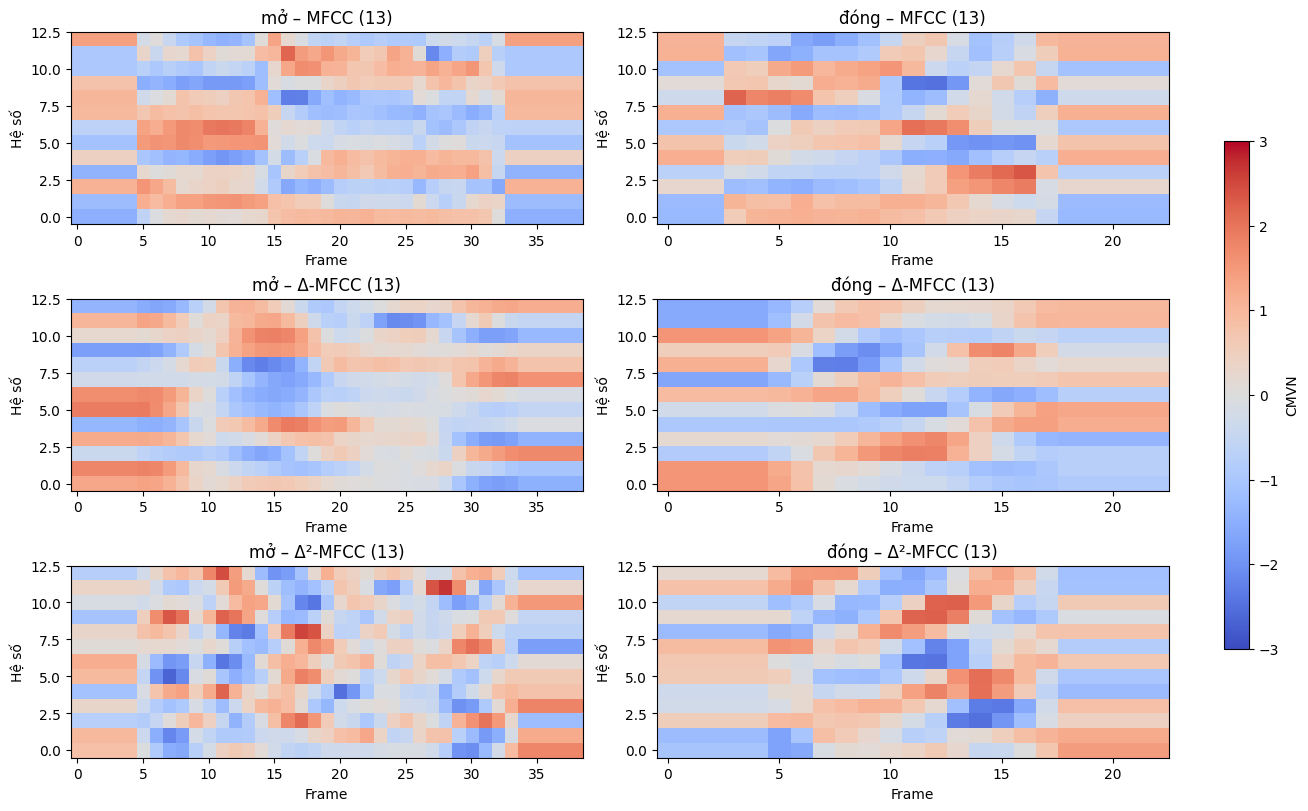

Phân tích: so sánh vùng biến đổi và thời điểm thay đổi các hệ số giữa hai từ; không khẳng định khác biệt nếu heatmap thực tế chưa cho thấy.


In [5]:
fig, axes = plt.subplots(3, 2, figsize=(13, 8), constrained_layout=True)
for c, label in enumerate(LABELS[:2]):
    feat = extract_features(str(wav_paths("train", label)[0]), "mfcc39")
    for r, title in enumerate(["MFCC (13)", "Δ-MFCC (13)", "Δ²-MFCC (13)"]):
        values = feat[:, r*13:(r+1)*13].T
        im = axes[r, c].imshow(values, aspect="auto", origin="lower", cmap="coolwarm", vmin=-3, vmax=3)
        axes[r, c].set_title(f"{LABEL_VI[label]} – {title}")
        axes[r, c].set_ylabel("Hệ số")
        axes[r, c].set_xlabel("Frame")
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.7, label="CMVN")
fig.savefig(FIG_DIR / "A_heatmap_2_words.png", dpi=150)
plt.show()
print("Phân tích: so sánh vùng biến đổi và thời điểm thay đổi các hệ số giữa hai từ; "
      "không khẳng định khác biệt nếu heatmap thực tế chưa cho thấy.")

## B–C. Khởi tạo và huấn luyện HMM trái-sang-phải
**Nguồn:** mục 4.2–4.3 và 5.3–5.4, trang 6–8.

- Mỗi từ một HMM `n_states=5` (thử `3,5,7` ở E1).
- `π=[1,0,...]`, cho phép `i→i` và `i→i+1`, state cuối tự lặp.
- `A[i,i]=0.7`, `A[i,i+1]=0.3`; Gaussian `diag`.
- Khởi tạo Gaussian bằng chia đều từng utterance theo thời gian để mô hình ổn định hơn với ít mẫu; sau đó **Baum–Welch** cập nhật tham số.
- Kiểm tra topology sau fit. Nếu `hmmlearn` phá topology, dừng và hướng dẫn chuyển sang cố định transition.

**Thông số `update_transitions`:** khi `True`, cho Baum–Welch cập nhật A; khi `False`, giữ cố định ma trận A (vẫn cập nhật Gaussian).

In [6]:
def make_lr_hmm(n_states=5, covariance_type="diag", update_transitions=True, n_iter=N_ITER):
    if n_states < 2:
        raise ValueError("Phải có ít nhất 2 state")
    model = GaussianHMM(
        n_components=n_states, covariance_type=covariance_type,
        n_iter=n_iter, tol=1e-3, min_covar=1e-3,
        init_params="",  # toàn bộ khởi tạo thủ công, tránh bị ghi đè
        params="tmc" if update_transitions else "mc",
        random_state=SEED, transmat_prior=1.0, implementation="log"
    )
    pi = np.zeros(n_states)
    pi[0] = 1.0
    A = np.zeros((n_states, n_states))
    for i in range(n_states - 1):
        A[i, i], A[i, i+1] = 0.7, 0.3
    A[-1, -1] = 1.0
    model.startprob_ = pi
    model.transmat_ = A
    return model


def init_emissions(model, sequences):
    """Khởi tạo thống kê Gaussian từ phân đoạn theo thời gian, không dùng test."""
    n = model.n_components
    d = sequences[0].shape[1]
    groups = [[] for _ in range(n)]
    for F in sequences:
        for i, ix in enumerate(np.array_split(np.arange(len(F)), n)):
            if len(ix):
                groups[i].append(F[ix])
    if any(len(g) == 0 for g in groups):
        raise ValueError("Không đủ frame để khởi tạo Gaussian cho từng state")
    segments = [np.vstack(g) for g in groups]
    model.n_features = d
    model.means_ = np.vstack([s.mean(axis=0) for s in segments])
    if model.covariance_type == "diag":
        model.covars_ = np.vstack([np.maximum(s.var(axis=0), 0.01) for s in segments])
    else:
        covs = []
        for s in segments:
            if len(s) <= 1:
                cov = np.eye(d) * 0.1
            else:
                cov = np.atleast_2d(np.cov(s, rowvar=False))
            covs.append(cov + np.eye(d) * 0.01)
        model.covars_ = np.stack(covs)
    return model


def topology_check(model, atol=1e-10):
    n = model.n_components
    allowed = np.eye(n, dtype=bool) | np.eye(n, k=1, dtype=bool)
    A = model.transmat_
    return (np.allclose(model.startprob_, np.r_[1.0, np.zeros(n-1)], atol=atol) and
            np.allclose(A[~allowed], 0.0, atol=atol) and
            np.allclose(A.sum(axis=1), 1.0, atol=1e-6))


def train_hmms(n_states=5, kind="mfcc39", covariance_type="diag",
               update_transitions=True, verbose=False):
    models, diagnostics = {}, []
    started = time.perf_counter()
    for label in LABELS:
        sequences = [extract_features(str(p), kind) for p in wav_paths("train", label)]
        X_concat = np.vstack(sequences)
        lengths = [len(s) for s in sequences]
        hmm = make_lr_hmm(n_states, covariance_type, update_transitions)
        init_emissions(hmm, sequences)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            hmm.fit(X_concat, lengths)
        if not topology_check(hmm):
            raise RuntimeError(
                f"Topology bị phá ở lớp {label}! Hãy thử update_transitions=False "
                "hoặc kiểm tra phiên bản hmmlearn.")
        models[label] = hmm
        diagnostics.append({"label": label, "n_states": n_states,
                            "n_features": X_concat.shape[1], "frames": len(X_concat),
                            "converged": bool(hmm.monitor_.converged),
                            "n_iter": int(hmm.monitor_.iter),
                            "last_log_prob": float(hmm.monitor_.history[-1]) if hmm.monitor_.history else np.nan,
                            "warnings": "; ".join(str(w.message) for w in caught)[:350]})
        if verbose:
            print(f"\n{label.upper()} - convergence: {hmm.monitor_.converged}")
            print(np.round(hmm.transmat_, 3))
    return models, pd.DataFrame(diagnostics), time.perf_counter()-started

models, convergence, hmm_train_seconds = train_hmms(verbose=True)
display(convergence)
convergence.to_csv(OUT / "C_convergence.csv", index=False, encoding="utf-8-sig")
for label, model in models.items():
    with (MODEL_DIR / f"hmm_{label}.pkl").open("wb") as f:
        pickle.dump({"label": label, "feature_kind": DEFAULT_FEATURE,
                     "sr": SR, "model": model}, f)
print(f"Đã lưu {len(models)} mô hình vào {MODEL_DIR}/; thời gian huấn luyện: {hmm_train_seconds:.2f}s")
print("CHÚ Ý: chỉ mở các file pickle do chính bạn tạo; không mở pickle không rõ nguồn gốc.")


MO - convergence: True
[[0.838 0.162 0.    0.    0.   ]
 [0.    0.889 0.111 0.    0.   ]
 [0.    0.    0.889 0.111 0.   ]
 [0.    0.    0.    0.932 0.068]
 [0.    0.    0.    0.    1.   ]]

DONG - convergence: True
[[0.829 0.171 0.    0.    0.   ]
 [0.    0.829 0.171 0.    0.   ]
 [0.    0.    0.75  0.25  0.   ]
 [0.    0.    0.    0.917 0.083]
 [0.    0.    0.    0.    1.   ]]

LEN - convergence: True
[[0.867 0.133 0.    0.    0.   ]
 [0.    0.878 0.122 0.    0.   ]
 [0.    0.    0.925 0.075 0.   ]
 [0.    0.    0.    0.9   0.1  ]
 [0.    0.    0.    0.    1.   ]]

XUONG - convergence: True
[[0.875 0.125 0.    0.    0.   ]
 [0.    0.898 0.102 0.    0.   ]
 [0.    0.    0.876 0.124 0.   ]
 [0.    0.    0.    0.915 0.085]
 [0.    0.    0.    0.    1.   ]]

DUNG - convergence: True
[[0.86  0.14  0.    0.    0.   ]
 [0.    0.88  0.12  0.    0.   ]
 [0.    0.    0.921 0.079 0.   ]
 [0.    0.    0.    0.912 0.088]
 [0.    0.    0.    0.    1.   ]]


,label,n_states,n_features,frames,converged,n_iter,last_log_prob,warnings
0,mo,5,39,263,True,39,-9551.601840,
1,dong,5,39,170,True,11,-5738.899587,
2,len,5,39,282,True,15,-11717.112470,
3,xuong,5,39,268,True,18,-10108.539895,
4,dung,5,39,283,True,13,-11682.719603,


Đã lưu 5 mô hình vào models/; thời gian huấn luyện: 0.21s
CHÚ Ý: chỉ mở các file pickle do chính bạn tạo; không mở pickle không rõ nguồn gốc.


## D. Nhận dạng maximum likelihood và Viterbi alignment
**Nguồn:** mục 4.4 và 5.5–5.6, trang 6–8.

Đối với cùng một utterance, tính `log P(X | λ_w)` ở tất cả năm HMM. Chọn **score lớn nhất**. Viterbi cho một đường state tốt nhất, khác Forward (tổng qua mọi đường).

In [7]:
def score_all(F, trained_models):
    return {label: float(model.score(F)) for label, model in trained_models.items()}


def predict_file(path, trained_models=models, kind="mfcc39", snr_db=None):
    F = extract_features(str(path), kind, snr_db)
    scores = score_all(F, trained_models)
    ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)
    return ranked[0][0], scores, F, ranked[0][1] - ranked[1][1]

score_rows = []
chosen = [(label, wav_paths("test", label)[0]) for label in LABELS[:3]]
for true_label, path in chosen:
    pred, scores, F, margin = predict_file(path)
    score_rows.append({"file": path.name, "true": true_label, "pred": pred,
                       "n_frames": len(F), "top1_top2_margin": margin, **scores})
score_table = pd.DataFrame(score_rows)
display(score_table.round(2))
score_table.to_csv(OUT / "D_acoustic_scores_3_test.csv", index=False, encoding="utf-8-sig")
print("Điểm lớn nhất = mô hình được chọn; không coi log-likelihood là xác suất %.")

,file,true,pred,n_frames,top1_top2_margin,mo,dong,len,xuong,dung
0,mo_07.wav,mo,mo,45,1546.99,-1911.75,-4317.05,-3458.74,-4853.94,-3730.46
1,dong_07.wav,dong,dong,29,247.37,-3351.99,-2107.53,-2354.90,-3310.00,-2622.59
2,len_07.wav,len,len,49,117.34,-5175.53,-4658.26,-3237.58,-5409.66,-3354.92


Điểm lớn nhất = mô hình được chọn; không coi log-likelihood là xác suất %.


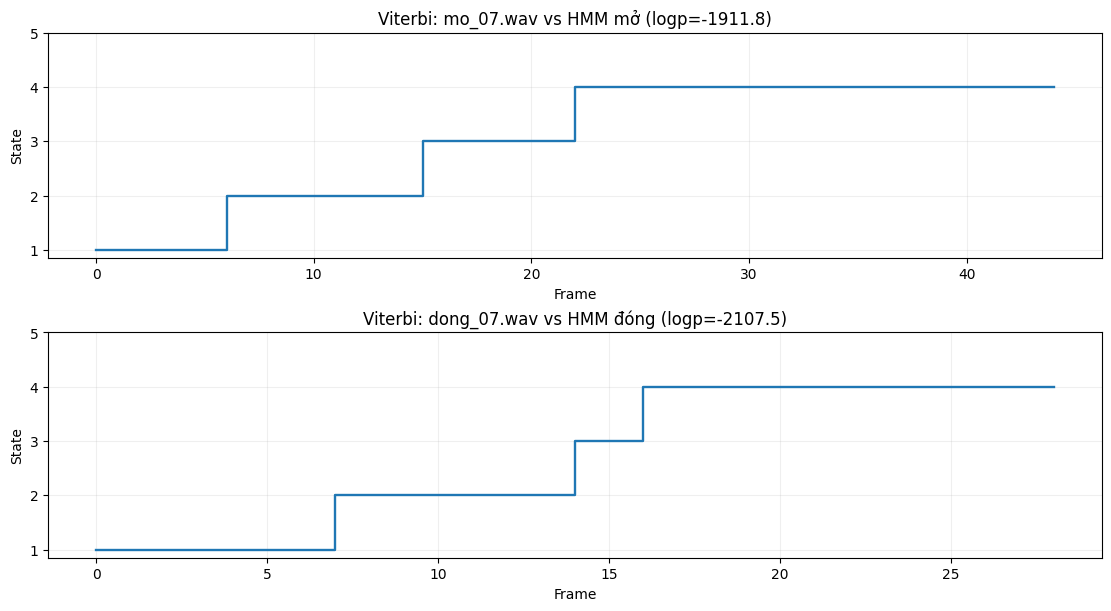

,label,file,logp,state_1_frames,state_2_frames,state_3_frames,state_4_frames,state_5_frames
0,mo,mo_07.wav,-1911.750014,6,9,7,23,0
1,dong,dong_07.wav,-2107.545701,7,7,2,13,0


Nếu một state giữ trong n frame, thời lượng xấp xỉ n × 10 ms (hop=160/16000s).


In [8]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), constrained_layout=True)
vit_rows = []
for ax, label in zip(axes, LABELS[:2]):
    path = wav_paths("test", label)[0]
    F = extract_features(str(path), "mfcc39")
    logp, states = models[label].decode(F, algorithm="viterbi")
    ax.step(np.arange(len(states)), states+1, where="post", linewidth=1.7)
    ax.set(title=f"Viterbi: {path.name} vs HMM {LABEL_VI[label]} (logp={logp:.1f})",
           xlabel="Frame", ylabel="State", yticks=list(range(1, N_STATES+1)))
    ax.grid(alpha=0.2)
    counts = np.bincount(states, minlength=N_STATES)
    vit_rows.append({"label": label, "file": path.name, "logp": logp,
                     **{f"state_{i+1}_frames": int(v) for i,v in enumerate(counts)}})
fig.savefig(FIG_DIR / "D_viterbi_two_words.png", dpi=150)
plt.show()
display(pd.DataFrame(vit_rows))
pd.DataFrame(vit_rows).to_csv(OUT / "D_viterbi_durations.csv", index=False, encoding="utf-8-sig")
print("Nếu một state giữ trong n frame, thời lượng xấp xỉ n × 10 ms (hop=160/16000s).")

## H (phần 1). Đánh giá tập test sạch — Accuracy và Confusion matrix
**Nguồn:** mục 4.8 và 5.7 trang 6, 9.

Với bài toán **1 từ/file**, accuracy + confusion matrix là chỉ số chính. Không dùng test để chọn lại tham số sau khi xem kết quả. Khi cần điều chỉnh, nên tách thêm validation từ tập train.

HMM test accuracy: 100.00% | 10 files | 0.04s


,file,true,pred,correct,margin_per_frame
0,mo_07.wav,mo,mo,True,34.377644
1,mo_08.wav,mo,mo,True,31.139503
2,dong_07.wav,dong,dong,True,8.530046
3,dong_08.wav,dong,dong,True,24.828658
4,len_07.wav,len,len,True,2.394763
5,len_08.wav,len,len,True,18.742837
6,xuong_07.wav,xuong,xuong,True,13.790164
7,xuong_08.wav,xuong,xuong,True,12.537277
8,dung_07.wav,dung,dung,True,19.278870
9,dung_08.wav,dung,dung,True,11.268159


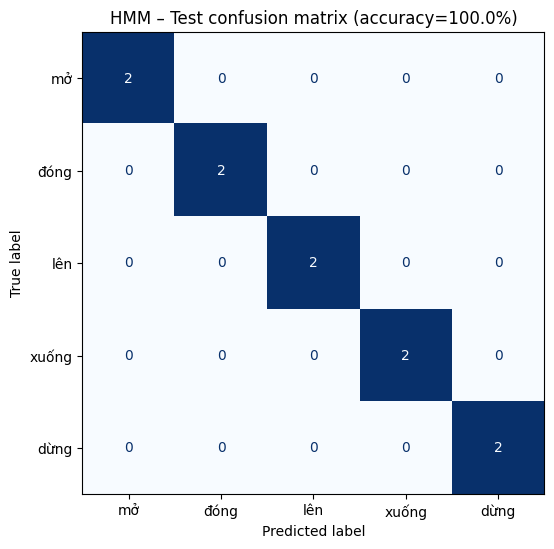

In [9]:
def evaluate_hmm(trained_models, kind="mfcc39", snr_db=None):
    started = time.perf_counter()
    rows = []
    for label in LABELS:
        for path in wav_paths("test", label):
            pred, scores, F, margin = predict_file(path, trained_models, kind, snr_db)
            ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)
            rows.append({"file": path.name, "true": label, "pred": pred,
                         "correct": pred == label, "frames": len(F),
                         "margin_per_frame": margin / len(F),
                         "true_score_per_frame": scores[label]/len(F),
                         "best_wrong_score_per_frame": max(v for k,v in scores.items() if k != label)/len(F),
                         **{f"score_{k}":v for k,v in scores.items()}})
    df = pd.DataFrame(rows)
    acc = accuracy_score(df.true, df.pred)
    return df, float(acc), time.perf_counter()-started

test_predictions, test_accuracy, hmm_test_seconds = evaluate_hmm(models)
print(f"HMM test accuracy: {test_accuracy:.2%} | {len(test_predictions)} files | {hmm_test_seconds:.2f}s")
display(test_predictions[["file", "true", "pred", "correct", "margin_per_frame"]])
test_predictions.to_csv(OUT / "H_predictions_clean.csv", index=False, encoding="utf-8-sig")

cm = confusion_matrix(test_predictions.true, test_predictions.pred, labels=LABELS)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=[LABEL_VI[x] for x in LABELS]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title(f"HMM – Test confusion matrix (accuracy={test_accuracy:.1%})")
fig.savefig(FIG_DIR / "H_confusion_HMM.png", dpi=150, bbox_inches="tight")
plt.show()

## E và E4. So sánh với MFCC + DTW từ Lab 2
**Nguồn:** mục 3.12, 4.5 và 5.8, trang 5, 6, 9.

- DTW dùng MFCC 13 chiều, **nearest-template**: lấy khoảng cách DTW nhỏ nhất đến bất kỳ mẫu train nào (cùng train/test split).
- Điểm DTW là **khoảng cách càng thấp càng tốt** (khác log-likelihood HMM).
- Điểm DTW chuẩn hóa theo tổng độ dài đường gần đúng `T_query + T_template`; công thức này cố định nhất quán cho các trial.
- So sánh accuracy, thời gian và confusion pair. Huấn luyện DTW chỉ là chuẩn bị và lưu template, không phải tối ưu mô hình như HMM.

**Chú ý:** để so sánh thực nghiệm công bằng hơn, có thể chạy thêm DTW-MFCC39 hoặc HMM-MFCC13 ở thí nghiệm E2. Trong bảng Lab 2 vs Lab 3, mỗi phương pháp dùng front-end trong bài tương ứng.

,method,accuracy,n_train_files,train_sec,test_sec,test_sec_per_file
0,DTW / MFCC13,0.9,30,0.044792,0.060334,0.006033
1,HMM / MFCC39,1.0,30,0.214564,0.044642,0.004464


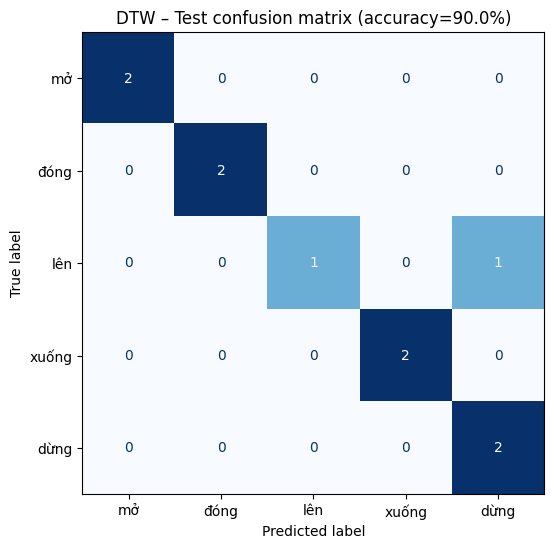

,file,true,pred_hmm,pred_dtw
4,len_07.wav,len,len,dung


Lưu ý: lần chạy đầu của DTW có thể bao gồm thời gian biên dịch JIT của librosa.


In [10]:
def prepare_dtw_templates(kind="mfcc13"):
    t0 = time.perf_counter()
    templates = [(label, path.name, extract_features(str(path), kind))
                 for label in LABELS for path in wav_paths("train", label)]
    return templates, time.perf_counter()-t0


def dtw_distance(A, B):
    D = librosa.sequence.dtw(X=A.T, Y=B.T, metric="euclidean", backtrack=False)
    return float(D[-1, -1] / (len(A) + len(B)))


def predict_dtw(F, templates):
    distances = [(dtw_distance(F, template), label, name) for label, name, template in templates]
    return min(distances)[1], min(distances)[0]


def evaluate_dtw(templates, kind="mfcc13"):
    t0 = time.perf_counter()
    rows = []
    for label in LABELS:
        for path in wav_paths("test", label):
            F = extract_features(str(path), kind)
            pred, distance = predict_dtw(F, templates)
            rows.append({"file": path.name, "true": label, "pred": pred,
                         "correct": pred == label, "distance": distance})
    df = pd.DataFrame(rows)
    return df, float(accuracy_score(df.true, df.pred)), time.perf_counter() - t0

templates, dtw_train_seconds = prepare_dtw_templates()
dtw_predictions, dtw_accuracy, dtw_test_seconds = evaluate_dtw(templates)
dtw_predictions.to_csv(OUT / "E_predictions_DTW.csv", index=False, encoding="utf-8-sig")
comparison = pd.DataFrame([
    {"method": "DTW / MFCC13", "accuracy": dtw_accuracy,
     "n_train_files": len(templates), "train_sec": dtw_train_seconds,
     "test_sec": dtw_test_seconds, "test_sec_per_file": dtw_test_seconds/len(dtw_predictions)},
    {"method": "HMM / MFCC39", "accuracy": test_accuracy,
     "n_train_files": sum(len(wav_paths("train",x)) for x in LABELS),
     "train_sec": hmm_train_seconds, "test_sec": hmm_test_seconds,
     "test_sec_per_file": hmm_test_seconds/len(test_predictions)}
])
display(comparison)
comparison.to_csv(OUT / "E_compare_DTW_vs_HMM.csv", index=False, encoding="utf-8-sig")

cm_dtw = confusion_matrix(dtw_predictions.true, dtw_predictions.pred, labels=LABELS)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm_dtw, display_labels=[LABEL_VI[x] for x in LABELS]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title(f"DTW – Test confusion matrix (accuracy={dtw_accuracy:.1%})")
fig.savefig(FIG_DIR / "E_confusion_DTW.png", dpi=150, bbox_inches="tight")
plt.show()

joined = test_predictions[["file","true","pred"]].merge(
    dtw_predictions[["file","true","pred"]], on=["file","true"], suffixes=("_hmm","_dtw"))
examples = joined.loc[(joined.pred_hmm == joined.true) != (joined.pred_dtw == joined.true)]
if len(examples):
    display(examples.head(10))
else:
    print("Chưa có trường hợp đúng/sai khác nhau trên tập test hiện tại; "
          "cần thêm mẫu/điều kiện khác để so sánh trường hợp cụ thể.")
print("Lưu ý: lần chạy đầu của DTW có thể bao gồm thời gian biên dịch JIT của librosa.")

## F. Lexicon mini (quy ước nhóm tự xây dựng)

Do giảng viên chưa cung cấp **phone inventory**, chúng ta dùng một bảng **minh họa tham khảo phát âm miền Bắc** trong `phone_inventory.txt`. Các token `T_*` là nhãn thanh điệu bổ sung, **không phải phone đoạn tính IPA**. Đây không phải lexicon chính thức; cần được giảng viên xác nhận nếu yêu cầu chuẩn phiên âm cụ thể.

**Yêu cầu phần F:** file `lexicon.txt` có 5 nhãn, parser tạo dictionary và giải thích rằng một word HMM có thể được cấu thành bằng phép nối các mô hình phone và các cạnh chuyển trạng thái theo chuỗi lexicon. **Không huấn luyện phone HMM trong Lab cơ bản.**


In [11]:
LEXICON_PATH = Path("lexicon.txt")
if not LEXICON_PATH.exists():
    raise FileNotFoundError("Chép lexicon.txt từ gói Lab03_FG_TuXayDung vào cùng cấp notebook.")

def parse_lexicon(path):
    lex = {}
    for line_no, line in enumerate(Path(path).read_text(encoding="utf-8-sig").splitlines(), 1):
        line = line.split("#", 1)[0].strip()
        if not line:
            continue
        parts = line.split()
        if len(parts) < 2:
            raise ValueError(f"Dòng {line_no}: thiếu phone")
        label, *phones = parts
        if label in lex:
            raise ValueError(f"Dòng {line_no}: nhãn trùng {label}")
        if any("<" in p or ">" in p for p in phones):
            raise ValueError(f"Dòng {line_no}: còn placeholder")
        lex[label] = phones
    return lex

lexicon = parse_lexicon(LEXICON_PATH)
assert set(lexicon) == set(LABELS), f"Lexicon không khớp nhãn: {set(lexicon) ^ set(LABELS)}"
print("F - Đã đọc", len(lexicon), "mục từ (quy ước minh họa, chưa xác nhận bởi giảng viên)")
for word, phones in lexicon.items():
    print(f"  {word:8s} -> {' '.join(phones)}")
print("Ghép word HMM từ phone HMM: nối topology của từng phone theo thứ tự lexicon; không huấn luyện phone-HMM trong lab này.")


F - Đã đọc 5 mục từ (quy ước minh họa, chưa xác nhận bởi giảng viên)
  mo       -> m əː T_HOI
  dong     -> ɗ ɔ ŋ T_SAC
  len      -> l e n T_NGANG
  xuong    -> s uə ŋ T_SAC
  dung     -> z ɯ ŋ T_HUYEN
Ghép word HMM từ phone HMM: nối topology của từng phone theo thứ tự lexicon; không huấn luyện phone-HMM trong lab này.


## G. Unigram/bigram add-k và MAP re-ranking

Do chưa có corpus giảng viên, file `corpus_tu_xay_dung.txt` được **tự tạo gồm các chuỗi lệnh giả định**, không phải dữ liệu ngôn ngữ thu thập hay câu nói liên tục. Corpus dùng để minh họa đếm cặp từ, xác suất có smoothing, và ảnh hưởng của hệ số λ lên xếp hạng acoustic. Kết quả LM không phản ánh phân bố ngôn ngữ tiếng Việt thực tế.

Phần thí nghiệm nên thử ít nhất 3 trọng số λ; chỉ tuyên bố LM sửa lỗi khi số liệu thực nghiệm cho thấy như vậy. Không sử dụng dữ liệu test để xây corpus hay chọn trọng số tối ưu.


In [12]:
CORPUS_PATH = Path("corpus_tu_xay_dung.txt")
if not CORPUS_PATH.exists():
    raise FileNotFoundError("Chép corpus_tu_xay_dung.txt từ gói Lab03_FG_TuXayDung vào cùng cấp notebook.")
print("Corpus nhóm tự xây dựng (minh họa):", CORPUS_PATH.resolve())

def count_ngrams(path, vocabulary):
    uni, bi, full_unigram = Counter(), Counter(), Counter()
    valid = set(vocabulary)
    lines = []
    for line in Path(path).read_text(encoding="utf-8-sig").splitlines():
        line = line.split("#", 1)[0].strip().lower()
        if not line: continue
        toks = line.split()
        bad = set(toks) - valid
        if bad: raise ValueError(f"Từ ngoài 5 nhãn: {sorted(bad)}")
        lines.append(toks)
        full_unigram.update(toks)
        for prev, cur in zip(toks[:-1], toks[1:]):
            uni[prev] += 1  # mẫu số bigram: số lần prev có từ đứng sau
            bi[(prev, cur)] += 1
    return uni, bi, full_unigram, lines

counts1, counts2, full_counts, corpus_lines = count_ngrams(CORPUS_PATH, LABELS)
V = len(LABELS)
K = 0.5

def bigram_prob(prev, cur, c1=counts1, c2=counts2, k=K, vocab_size=V):
    return (c2[(prev, cur)] + k) / (c1[prev] + k * vocab_size)

print("G - Số chuỗi:", len(corpus_lines))
print("Unigram:", dict(full_counts))
print("Bigram:", {f"{a}->{b}":n for (a,b),n in counts2.items()})
pd.DataFrame([{"word":w,"count":full_counts[w]} for w in LABELS]).to_csv(OUT / "G_unigram_counts.csv", index=False, encoding="utf-8-sig")
pd.DataFrame([{"previous":a,"current":b,"count":counts2[(a,b)]} for a in LABELS for b in LABELS]).to_csv(OUT / "G_bigram_counts.csv",index=False,encoding="utf-8-sig")
bigram_table = pd.DataFrame([[bigram_prob(a,b) for b in LABELS] for a in LABELS], index=LABELS, columns=LABELS)
display(bigram_table.round(3))
assert np.allclose(bigram_table.sum(axis=1), 1.0)
bigram_table.to_csv(OUT / "G_bigram_probabilities.csv", encoding="utf-8-sig")


Corpus nhóm tự xây dựng (minh họa): C:\xulyamthanh\lab03_2351260688_NguyenNgocTien\corpus_tu_xay_dung.txt
G - Số chuỗi: 30
Unigram: {'mo': 12, 'len': 13, 'dung': 30, 'xuong': 13, 'dong': 12}
Bigram: {'mo->len': 4, 'len->dung': 11, 'mo->xuong': 2, 'xuong->dung': 11, 'dong->len': 2, 'dong->xuong': 4, 'mo->dung': 4, 'dong->dung': 4, 'len->xuong': 2, 'xuong->len': 2, 'mo->dong': 2, 'dong->mo': 2}


,mo,dong,len,xuong,dung
mo,0.034,0.172,0.310,0.172,0.310
dong,0.172,0.034,0.172,0.310,0.310
len,0.032,0.032,0.032,0.161,0.742
xuong,0.032,0.032,0.161,0.032,0.742
dung,0.200,0.200,0.200,0.200,0.200


In [13]:
def lm_rerank(F, previous_word, trained_models, weight, c1=counts1, c2=counts2):
    if previous_word not in LABELS:
        raise ValueError(f"previous_word cần thuộc {LABELS}")
    acoustic = {w: trained_models[w].score(F) / len(F) for w in LABELS}
    log_lm = {w: math.log(bigram_prob(previous_word, w, c1, c2)) for w in LABELS}
    total = {w: acoustic[w] + weight * log_lm[w] for w in LABELS}
    return max(total, key=total.get), acoustic, total

ambiguous = test_predictions.sort_values("margin_per_frame").iloc[0]
ambiguous_path = next(p for p in wav_paths("test", ambiguous.true) if p.name == ambiguous.file)
F_amb = extract_features(str(ambiguous_path), "mfcc39")
PREVIOUS_WORD = "mo"  # ngữ cảnh mô phỏng, không phải audio của một câu liên tục
lm_rows = []
for weight in LM_WEIGHTS:
    pred, acoustic, combined = lm_rerank(F_amb, PREVIOUS_WORD, models, weight)
    for w in LABELS:
        lm_rows.append({"file": ambiguous_path.name, "true": ambiguous.true,
             "previous": PREVIOUS_WORD, "lambda_lm": weight,
             "candidate":w, "acoustic_score_frame":acoustic[w],
             "lm_logprob":math.log(bigram_prob(PREVIOUS_WORD,w)),
             "combined_score":combined[w],"candidate_selected":w==pred})
lm_df = pd.DataFrame(lm_rows)
display(lm_df)
lm_df.to_csv(OUT / "G_E6_lm_reranking_detailed.csv", index=False, encoding="utf-8-sig")
print("Corpus và previous-word context đều là minh họa; kết quả không phải full decoder ASR.")


,file,true,previous,lambda_lm,candidate,acoustic_score_frame,lm_logprob,combined_score,candidate_selected
0,len_07.wav,len,mo,0.0,mo,-105.623041,-3.367296,-105.623041,False
1,len_07.wav,len,mo,0.0,dong,-95.066572,-1.757858,-95.066572,False
2,len_07.wav,len,mo,0.0,len,-66.073053,-1.170071,-66.073053,True
3,len_07.wav,len,mo,0.0,xuong,-110.401252,-1.757858,-110.401252,False
4,len_07.wav,len,mo,0.0,dung,-68.467817,-1.170071,-68.467817,False
5,len_07.wav,len,mo,0.1,mo,-105.623041,-3.367296,-105.959771,False
6,len_07.wav,len,mo,0.1,dong,-95.066572,-1.757858,-95.242358,False
7,len_07.wav,len,mo,0.1,len,-66.073053,-1.170071,-66.190061,True
8,len_07.wav,len,mo,0.1,xuong,-110.401252,-1.757858,-110.577038,False
9,len_07.wav,len,mo,0.1,dung,-68.467817,-1.170071,-68.584824,False


Corpus và previous-word context đều là minh họa; kết quả không phải full decoder ASR.


## E1–E3. Siêu tham số và ablation
**Nguồn:** phần 6, trang 10.

- **E1:** số state `3,5,7` → accuracy, convergence, thời gian train.
- **E2:** `MFCC13` vs `MFCC39` → accuracy/confusion trên cùng split.
- **E3:** `diag` vs `full` covariance **chỉ khi có đủ dữ liệu**; với bộ 6 bản ghi/từ, full covariance 39 chiều có nguy cơ overfit. Mặc định `RUN_FULL_COV=False`; bật nếu bạn có nhiều dữ liệu và muốn kiểm tra.

**Quy tắc:** không dùng kết quả của test để liên tục chọn tham số cuối. Các thí nghiệm mô tả hành vi; khi cần chọn hyperparameter, phải tạo validation từ train.

Model is not converging.  Current: -8895.051756703633 is not greater than -8895.051687072071. Delta is -6.963156192796305e-05


,n_states,accuracy,train_sec,test_sec,all_converged,iters_mean,error
0,3,0.9,0.130648,0.010125,True,19.0,
1,5,1.0,0.151795,0.012009,True,19.2,
2,7,0.9,0.126836,0.013849,True,14.0,


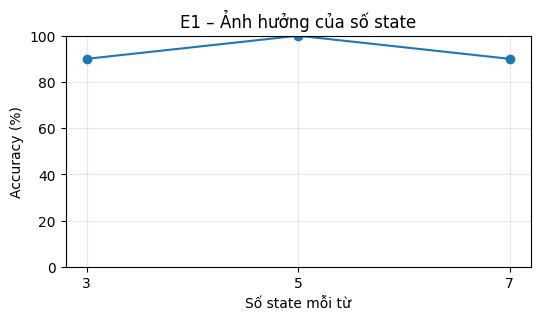

In [14]:
e1_rows = []
for n_states in [3, 5, 7]:
    try:
        trial_models, diag_df, train_sec = train_hmms(n_states=n_states, kind="mfcc39")
        preds, acc, test_sec = evaluate_hmm(trial_models, kind="mfcc39")
        e1_rows.append({"n_states": n_states, "accuracy": acc, "train_sec":train_sec,
                        "test_sec":test_sec, "all_converged":diag_df.converged.all(),
                        "iters_mean":diag_df.n_iter.mean(), "error":""})
    except Exception as ex:
        e1_rows.append({"n_states":n_states,"accuracy":np.nan, "train_sec":np.nan,
                        "test_sec":np.nan,"all_converged":False,"iters_mean":np.nan,
                        "error":f"{type(ex).__name__}: {ex}"})
e1_df = pd.DataFrame(e1_rows)
display(e1_df)
e1_df.to_csv(OUT / "E1_states_3_5_7.csv", index=False, encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(e1_df.n_states, e1_df.accuracy * 100, marker="o")
ax.set(xlabel="Số state mỗi từ", ylabel="Accuracy (%)", title="E1 – Ảnh hưởng của số state", xticks=[3,5,7], ylim=(0,100))
ax.grid(alpha=0.3)
fig.savefig(FIG_DIR / "E1_states_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

Model is not converging.  Current: -1680.885327311652 is not greater than -1680.8853202238324. Delta is -7.087819540174678e-06


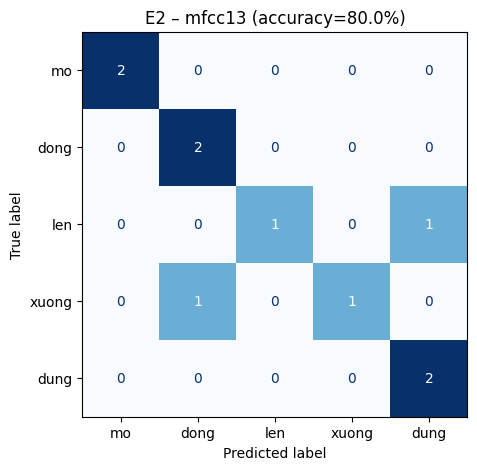

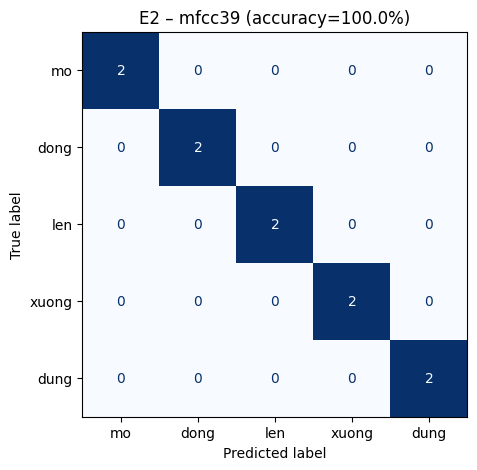

,features,dimension,accuracy,train_sec,test_sec,all_converged,error
0,mfcc13,13,0.8,0.112700,0.023366,True,
1,mfcc39,39,1.0,0.119377,0.009133,True,


In [15]:
e2_rows = []
for kind in ["mfcc13", "mfcc39"]:
    try:
        trial_models, status, sec = train_hmms(n_states=5, kind=kind)
        preds, acc, pred_sec = evaluate_hmm(trial_models, kind=kind)
        e2_rows.append({"features":kind, "dimension": 13 if kind=="mfcc13" else 39,
                        "accuracy":acc,"train_sec":sec,"test_sec":pred_sec,
                        "all_converged":status.converged.all(),"error":""})
        cm_this = confusion_matrix(preds.true, preds.pred, labels=LABELS)
        fig, ax = plt.subplots(figsize=(6,5))
        ConfusionMatrixDisplay(cm_this, display_labels=LABELS).plot(ax=ax, cmap="Blues",colorbar=False)
        ax.set_title(f"E2 – {kind} (accuracy={acc:.1%})")
        fig.savefig(FIG_DIR / f"E2_confusion_{kind}.png",dpi=150,bbox_inches="tight")
        plt.show()
    except Exception as ex:
        e2_rows.append({"features":kind,"dimension":13 if kind=="mfcc13" else 39,
                        "accuracy":np.nan,"train_sec":np.nan,"test_sec":np.nan,
                        "all_converged":False,"error":f"{type(ex).__name__}: {ex}"})
e2_df = pd.DataFrame(e2_rows)
display(e2_df)
e2_df.to_csv(OUT / "E2_mfcc13_vs_mfcc39.csv", index=False, encoding="utf-8-sig")

In [16]:
# E3: diagonal vs full. Full covariance chỉ phù hợp khi đủ dữ liệu (theo PDF).
def train_logscore(model_dict):
    vals=[]
    for label in LABELS:
        for path in wav_paths("train",label):
            F=extract_features(str(path),"mfcc39")
            vals.append(model_dict[label].score(F)/len(F))
    return float(np.mean(vals))

e3_rows=[{"covariance_type":"diag", "accuracy":test_accuracy,
          "train_score_per_frame":train_logscore(models),
          "test_true_score_per_frame":float(test_predictions.true_score_per_frame.mean()),
          "train_sec":hmm_train_seconds,"note":"Cấu hình cơ sở"}]
if RUN_FULL_COV:
    try:
        full_models, full_status, sec = train_hmms(n_states=5,kind="mfcc39",covariance_type="full")
        full_predictions, acc, _ = evaluate_hmm(full_models)
        e3_rows.append({"covariance_type":"full", "accuracy":acc,
            "train_score_per_frame":train_logscore(full_models),
            "test_true_score_per_frame":float(full_predictions.true_score_per_frame.mean()),
            "train_sec":sec, "note":"So sánh train/test; nguy cơ overfit nếu dữ liệu ít"})
    except Exception as ex:
        e3_rows.append({"covariance_type":"full","accuracy":np.nan,
                        "note":f"Không chạy được: {type(ex).__name__}: {ex}"})
else:
    e3_rows.append({"covariance_type":"full","accuracy":np.nan,
                    "note":"Chưa chạy: Lab 3 cho phép thử full nếu đủ dữ liệu; đặt RUN_FULL_COV=True"})
e3_df=pd.DataFrame(e3_rows)
display(e3_df)
e3_df.to_csv(OUT/"E3_diag_vs_full.csv",index=False,encoding="utf-8-sig")


,covariance_type,accuracy,train_score_per_frame,test_true_score_per_frame,train_sec,note
0,diag,1.0,-38.040921,-55.554024,0.214564,Cấu hình cơ sở
1,full,NaN,NaN,NaN,NaN,Chưa chạy: Lab 3 cho phép thử full nếu đủ dữ l...


## E5 và H (phần 2). Robustness với nhiễu; phân bố score và ngưỡng reject
**Nguồn:** mục 4.8 và phần 6, trang 6, 10.

- Tạo bản *test-only* với nhiễu Gaussian trắng **SNR 15 dB**. Không làm nhiễu train và không sửa file WAV gốc.
- So sánh accuracy sạch/nhiễu (đây là mismatch môi trường, **không** thay thế bài thử người nói mới).
- Vẽ score/frame của lớp đúng và đối thủ mạnh nhất.
- Gợi ý ngưỡng reject dựa trên percentile score **của train**, không tinh chỉnh bằng test. Tài liệu không có nhãn `unknown`, nên **chưa thể đo khả năng nhận unknown** nếu không thu thêm dữ liệu.

,condition,accuracy,test_sec,accuracy_drop_vs_clean
0,clean,1.0,0.044642,0.0
1,white_noise_15dB,0.5,0.032192,0.5


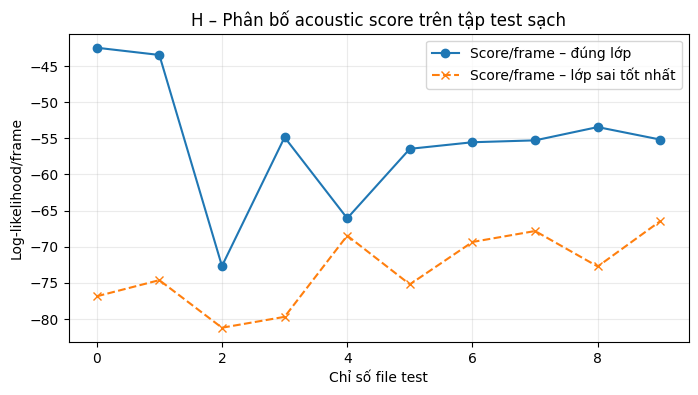

In [17]:
noisy_predictions, noisy_acc, noisy_sec = evaluate_hmm(models, snr_db=NOISE_SNR_DB)
robustness = pd.DataFrame([
    {"condition":"clean", "accuracy":test_accuracy, "test_sec":hmm_test_seconds},
    {"condition":f"white_noise_{NOISE_SNR_DB:g}dB", "accuracy":noisy_acc,"test_sec":noisy_sec}
])
robustness["accuracy_drop_vs_clean"] = test_accuracy - robustness.accuracy
display(robustness)
robustness.to_csv(OUT / "E5_noise_robustness.csv", index=False, encoding="utf-8-sig")
noisy_predictions.to_csv(OUT / "H_predictions_noisy.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(8,4))
order = np.arange(len(test_predictions))
ax.plot(order, test_predictions.true_score_per_frame, "o-", label="Score/frame – đúng lớp")
ax.plot(order, test_predictions.best_wrong_score_per_frame, "x--", label="Score/frame – lớp sai tốt nhất")
ax.set(xlabel="Chỉ số file test",ylabel="Log-likelihood/frame",
       title="H – Phân bố acoustic score trên tập test sạch")
ax.legend()
ax.grid(alpha=0.25)
fig.savefig(FIG_DIR / "H_true_vs_wrong_scores.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
train_scores = []
for label in LABELS:
    for path in wav_paths("train", label):
        F = extract_features(str(path), "mfcc39")
        train_scores.append(models[label].score(F) / len(F))
# Ví dụ minh họa ngưỡng từ train; không đủ để xác thực OOV/unknown.
reject_threshold = float(np.percentile(train_scores, 5))
reject_df = test_predictions[["file", "true", "pred", "frames"]].copy()
reject_df["best_score_per_frame"] = [
    max(float(row[f"score_{w}"]) for w in LABELS) / int(row.frames)
    for _, row in test_predictions.iterrows()
]
reject_df["pred_with_reject"] = np.where(
    ENABLE_REJECT_IN_DEMO & (reject_df.best_score_per_frame < reject_threshold),
    "unknown", reject_df.pred
)
reject_df["would_reject_with_train_threshold"] = reject_df.best_score_per_frame < reject_threshold
print(f"Ngưỡng đề xuất sơ bộ (5th percentile train true score/frame): {reject_threshold:.3f}")
print("Đây KHÔNG phải ngưỡng tối ưu. Reject đang TẮT mặc định; cần validation có OOV để sử dụng thật.")
display(reject_df)
reject_df.to_csv(OUT / "H_reject_demo.csv",index=False,encoding="utf-8-sig")

Ngưỡng đề xuất sơ bộ (5th percentile train true score/frame): -46.770
Đây KHÔNG phải ngưỡng tối ưu. Reject đang TẮT mặc định; cần validation có OOV để sử dụng thật.


,file,true,pred,frames,best_score_per_frame,pred_with_reject,would_reject_with_train_threshold
0,mo_07.wav,mo,mo,45,-42.483322,mo,False
1,mo_08.wav,mo,mo,55,-43.484348,mo,False
2,dong_07.wav,dong,dong,29,-72.673354,dong,True
3,dong_08.wav,dong,dong,39,-54.869689,dong,True
4,len_07.wav,len,len,49,-66.073053,len,True
5,len_08.wav,len,len,52,-56.463635,len,True
6,xuong_07.wav,xuong,xuong,45,-55.554156,xuong,True
7,xuong_08.wav,xuong,xuong,52,-55.293645,xuong,True
8,dung_07.wav,dung,dung,45,-53.457333,dung,True
9,dung_08.wav,dung,dung,52,-55.187700,dung,True


## Tổng hợp thực nghiệm & checklist nộp bài
**Thí nghiệm:** E1 = số state; E2 = 13/39 chiều; E3 = diag/full khi đủ data; E4 = DTW/HMM; E5 = clean/noise; E6 = λLM.  
**Sản phẩm:** notebook, HMM serialized, bảng likelihood, ≥2 Viterbi paths, 2 confusion matrices, bảng DTW/HMM, lexicon từ giảng viên, corpus do giảng viên cung cấp và báo cáo 4–6 trang.

### Gợi ý trả lời báo cáo
1. Forward **cộng** qua các đường trạng thái; Viterbi chọn đường có xác suất **lớn nhất**.
2. γ là trách nhiệm của state cho frame; ξ là trách nhiệm của transition cho cặp frame.
3. Baum–Welch có thể hội tụ nghiệm xấu do ít dữ liệu, khởi tạo chưa tốt, số state quá lớn.
4. `diag` có ít tham số hơn `full`, phù hợp dữ liệu nhỏ và 39 chiều.
5. Δ, Δ² đưa biến thiên cục bộ vào observation dù HMM đã quản lý thứ tự state theo thời gian.
6. Whole-word HMM không cần lexicon; ghép phone HMM thành từ thì cần lexicon.
7. Self-loop cho phép kéo dài trạng thái khi người nói nói chậm.
8. Trong **cùng** utterance, chia log-likelihood cho T không đổi kết quả `argmax`.
9. DTW alignment căn chỉnh **hai chuỗi đặc trưng**; Viterbi alignment căn chỉnh **chuỗi frame với state ẩn**.
10. Với từ ngoài vocabulary, argmax vẫn chọn nhãn trong 5 lớp; cần ngưỡng reject và dữ liệu OOV để đánh giá.

> Các nhận xét trong báo cáo phải được thay bằng **số liệu thực tế do notebook sinh ra**, không sao chép kết quả ví dụ.

In [19]:
summary = {
    "files_total": int(len(inventory)),
    "train_files": int((inventory.split=="train").sum()),
    "test_files": int((inventory.split=="test").sum()),
    "hmm_accuracy": float(test_accuracy),
    "dtw_accuracy": float(dtw_accuracy),
    "hmm_train_sec": float(hmm_train_seconds),
    "hmm_test_sec": float(hmm_test_seconds),
    "dtw_prepare_sec": float(dtw_train_seconds),
    "dtw_test_sec": float(dtw_test_seconds),
    "noisy_accuracy": float(noisy_acc),
    "noise_snr_db": NOISE_SNR_DB,
    "lexicon_entries": int(len(lexicon)),
    "using_demo_corpus": CORPUS_PATH.name == "corpus_demo.txt",
    "E3_full_cov_run": RUN_FULL_COV,
}
summary_df = pd.DataFrame(list(summary.items()),columns=["metric", "value"])
display(summary_df)
summary_df.to_csv(OUT / "FINAL_summary.csv", index=False, encoding="utf-8-sig")
print("HOÀN TẤT: Kiểm tra results/*.csv, results/figures/*.png và models/*.pkl")
if summary["using_demo_corpus"]:
    print("CẦN LÀM TRƯỚC KHI NỘP: thay corpus DEMO bằng corpus giảng viên.")
if summary["lexicon_entries"] < len(LABELS):
    print("CẦN LÀM TRƯỚC KHI NỘP: hoàn thiện lexicon.txt bằng phone chuẩn do giảng viên cung cấp.")
print("CẦN VIẾT: báo cáo PDF/DOCX 4–6 trang từ các bảng và hình ở thư mục results/.")

,metric,value
0,files_total,40
1,train_files,30
2,test_files,10
3,hmm_accuracy,1.0
4,dtw_accuracy,0.9
5,hmm_train_sec,0.214564
6,hmm_test_sec,0.044642
7,dtw_prepare_sec,0.044792
8,dtw_test_sec,0.060334
9,noisy_accuracy,0.5


HOÀN TẤT: Kiểm tra results/*.csv, results/figures/*.png và models/*.pkl
CẦN VIẾT: báo cáo PDF/DOCX 4–6 trang từ các bảng và hình ở thư mục results/.


## Bổ sung kiểm định theo rubric Lab 3 (các mục 4, 6, 7)

Các kiểm tra dưới đây giúp phát hiện tình trạng chưa đủ điều kiện để kết luận từ dữ liệu tổng hợp: speaker metadata, Viterbi kết thúc ở state nào, sự phụ thuộc kết quả vào ngữ cảnh bigram, khoảng cách top-1/top-2 và định dạng đầu ra.

**Lưu ý:** HMM `hmmlearn` mặc định tính likelihood với tổng mọi state cuối; Lab 3 không yêu cầu ràng buộc bắt buộc phải kết thúc ở state cuối. State path kết thúc ở state 4/5 không nhất thiết vi phạm topology left-to-right.

In [20]:
# Viterbi diagnostics trên TẤT CẢ test utterance; không giả định final-state constraint.
path_rows=[]
for label in LABELS:
    for path in wav_paths("test",label):
        F=extract_features(str(path))
        logp, states=models[label].decode(F,algorithm="viterbi")
        counts=np.bincount(states,minlength=N_STATES)
        path_rows.append({"file":path.name,"true":label,"n_frames":len(F),
                          "first_state":int(states[0])+1,"last_state":int(states[-1])+1,
                          "n_backward":int(np.sum(np.diff(states)<0)),
                          "n_skips":int(np.sum(np.diff(states)>1)),
                          "logp_viterbi":float(logp),
                          **{f"state_{k+1}_frames":int(v) for k,v in enumerate(counts)}})
viterbi_all=pd.DataFrame(path_rows)
display(viterbi_all)
viterbi_all.to_csv(OUT/"D_viterbi_all_paths.csv",index=False,encoding="utf-8-sig")
assert not viterbi_all.n_backward.any() and not viterbi_all.n_skips.any()
print("Các đường đi không chuyển ngược/skip; last_state != n_states vẫn có thể hợp lệ theo Lab 3.")


,file,true,n_frames,first_state,last_state,n_backward,n_skips,logp_viterbi,state_1_frames,state_2_frames,state_3_frames,state_4_frames,state_5_frames
0,mo_07.wav,mo,45,1,4,0,0,-1911.750014,6,9,7,23,0
1,mo_08.wav,mo,55,1,4,0,0,-2392.111853,6,12,8,29,0
2,dong_07.wav,dong,29,1,4,0,0,-2107.545701,7,7,2,13,0
3,dong_08.wav,dong,39,1,4,0,0,-2139.924172,8,7,4,20,0
4,len_07.wav,len,49,1,5,0,0,-3237.985937,8,19,3,16,3
5,len_08.wav,len,52,1,5,0,0,-2936.925235,7,9,18,12,6
6,xuong_07.wav,xuong,45,1,5,0,0,-2500.402643,9,9,8,16,3
7,xuong_08.wav,xuong,52,1,4,0,0,-2875.696480,9,10,10,23,0
8,dung_07.wav,dung,45,1,5,0,0,-2405.585376,9,10,10,10,6
9,dung_08.wav,dung,52,1,5,0,0,-2869.763288,9,8,16,13,6


Các đường đi không chuyển ngược/skip; last_state != n_states vẫn có thể hợp lệ theo Lab 3.


In [21]:
# E6 mở rộng: thử mọi ngữ cảnh giả định cho utterance có acoustic margin thấp nhất.
# Kết quả là phân tích sư phạm, KHÔNG phải câu liên tục hoặc bằng chứng về corpus thực.
context_rows=[]
for prev in LABELS:
    for weight in LM_WEIGHTS:
        pred, acoustic, combined=lm_rerank(F_amb, prev, models, weight)
        context_rows.append({"file":ambiguous_path.name,"previous":prev,
                             "lambda_lm":weight,"pred":pred,
                             "acoustic_top":max(acoustic,key=acoustic.get),
                             "decision_changed":pred!=max(acoustic,key=acoustic.get)})
context_df=pd.DataFrame(context_rows)
display(context_df)
context_df.to_csv(OUT/"E6_all_contexts.csv",index=False,encoding="utf-8-sig")
if not context_df.decision_changed.any():
    print("LM chưa đổi quyết định ở các trọng số thử: không tạo kết luận rằng LM đã cải thiện accuracy.")


,file,previous,lambda_lm,pred,acoustic_top,decision_changed
0,len_07.wav,mo,0.0,len,len,False
1,len_07.wav,mo,0.1,len,len,False
2,len_07.wav,mo,0.3,len,len,False
3,len_07.wav,mo,1.0,len,len,False
4,len_07.wav,dong,0.0,len,len,False
5,len_07.wav,dong,0.1,len,len,False
6,len_07.wav,dong,0.3,len,len,False
7,len_07.wav,dong,1.0,len,len,False
8,len_07.wav,len,0.0,len,len,False
9,len_07.wav,len,0.1,len,len,False


In [ ]:
# Kiểm tra speaker/source metadata nếu người dùng có cung cấp.
metadata_candidates=[Path("metadata.csv"),DATASET_ROOT/"metadata.csv"]
metadata_file=next((p for p in metadata_candidates if p.exists()),None)
if metadata_file is None:
    print("Chưa có metadata nguồn giọng. Không thể chứng minh split theo speaker. Hãy cung cấp speaker_id và source_model cho từng WAV.")
else:
    meta=pd.read_csv(metadata_file)
    print("Metadata:",metadata_file)
    display(meta.head(10))
    if {"split","speaker_id"}.issubset(meta.columns):
        train_ids=set(meta.loc[meta["split"]=="train","speaker_id"].dropna().astype(str))
        test_ids=set(meta.loc[meta["split"]=="test","speaker_id"].dropna().astype(str))
        overlap=train_ids & test_ids
        print("Speaker overlap train/test:",sorted(overlap))
        if overlap: print("CHÚ Ý: đây không phải speaker-independent evaluation.")
    else:
        print("Thiếu cột split/speaker_id: không kiểm chứng được speaker independence.")


Metadata: metadata.csv


,relative_path,label,text,speaker_id,voice_variant,voice_type,dialect_variant,train_test,speech_source,phonetic_symbols_espeak,duration_sec,sha256
0,dataset/train/mo/mo_01.wav,mo,mở,S01,vi+m1,Nam,Bắc,train,eSpeak synthetic voice variant (NOT a real spe...,m'@:4_|,0.900,8a9e64cf5e4664c3307a2ba1ab269975f92f3ecb3b0b3d...
1,dataset/train/mo/mo_02.wav,mo,mở,S02,vi-hue+m2,Nam,Huế,train,eSpeak synthetic voice variant (NOT a real spe...,m'@:4_|,1.086,82c43c0f253a27f1c91a58be6cce5991e904c6e2c295f5...
2,dataset/train/mo/mo_03.wav,mo,mở,S03,vi-sgn+m3,Nam,Nam,train,eSpeak synthetic voice variant (NOT a real spe...,m'@:4_|,0.903,0014c248b460967c613ba96a1988ed3513d28afc0b10df...
3,dataset/train/mo/mo_04.wav,mo,mở,S04,vi+m4,Nam,Bắc,train,eSpeak synthetic voice variant (NOT a real spe...,m'@:4_|,1.030,5e2adcfeaa8831075a61a1f83d1444c4d0ddfadcb221bb...
4,dataset/train/mo/mo_05.wav,mo,mở,S05,vi+f1,Nữ,Bắc,train,eSpeak synthetic voice variant (NOT a real spe...,m'@:4_|,0.913,8c82c8b5a84319d7cc729b0694cfddbef7ccedf409515e...
5,dataset/train/mo/mo_06.wav,mo,mở,S06,vi-hue+f2,Nữ,Huế,train,eSpeak synthetic voice variant (NOT a real spe...,m'@:4_|,1.073,881ce8d6d024d820409c377c5f13663e44a42924746154...
6,dataset/test/mo/mo_07.wav,mo,mở,S07,vi-sgn+f3,Nữ,Nam,test,eSpeak synthetic voice variant (NOT a real spe...,m'@:4_|,1.022,880ac0c3d3aa40ec6565708c798e6b921c04debaf15845...
7,dataset/test/mo/mo_08.wav,mo,mở,S08,vi+f4,Nữ,Bắc,test,eSpeak synthetic voice variant (NOT a real spe...,m'@:4_|,1.053,13e151f1bb341e199666ac54983282d71edaf2d6031c10...
8,dataset/train/dong/dong_01.wav,dong,đóng,S01,vi+m1,Nam,Bắc,train,eSpeak synthetic voice variant (NOT a real spe...,d_'O#3_|,0.851,8e0251bade1af86425698bcabe920f28ffebb9d7b30783...
9,dataset/train/dong/dong_02.wav,dong,đóng,S02,vi-hue+m2,Nam,Huế,train,eSpeak synthetic voice variant (NOT a real spe...,d_'O#3_|,0.966,ceaddaef7168cbeb6c55decfc04906b5c277896a4d2780...


Thiếu cột split/speaker_id: không kiểm chứng được speaker independence.


: 

### Checklist cuối cùng trước khi nộp (không tự động xác nhận)

- **A–E, H:** đọc bảng `results/`, kiểm tra hội tụ, confusion matrix và hai Viterbi plots.
- **F:** `lexicon.txt` phải có 5 mục từ và phone sequence theo cùng một inventory được giảng viên xác nhận; nếu chưa có, ghi *chưa hoàn thành*, không tự giả danh chuẩn.
- **G/E6:** thay `corpus_demo.txt` bằng `corpus_giang_vien.txt` nếu đã có corpus chính thức; thử 0, 0.1, 0.3, 1.0 và ghi rõ khi LM không thay đổi quyết định.
- **E3:** chỉ bật `RUN_FULL_COV=True` khi đủ dữ liệu; nếu không, giải thích đúng theo mục 6 trong PDF.
- **Reject:** chỉ sử dụng ngưỡng sau khi đánh giá trên validation có OOV.
- **Báo cáo:** nộp notebook, `models/`, kết quả, README, 4–6 trang báo cáo; nêu giới hạn 40 mẫu TTS và chưa đại diện cho tiếng nói người thật.